# ```QISKIT FALL FEST AT THE UNIVERSITY OF OKLAHOMA (Fall 2026)```

## ```Event 3: Qiskit and Quantum Computation```

This notebook introduces foundational concepts in quantum computing using Qiskit. We begin by exploring how quantum states are prepared, transformed, and measured, building up the basic workflow of a quantum circuit: initialize a qubit, apply quantum gates, and read out the result.

The notebook is structured around three core ideas:

- State preparation, transformation, and measurement: understanding how qubits are initialized, evolved through operations, and observed through measurement.
- The Bloch sphere: a geometric representation of a single qubit that helps visualize quantum states and gate operations as rotations in space.
- Multi-qubit systems: extending the concepts from one qubit to several qubits, including correlated states and entanglement.

Together, these topics form the basis of quantum computation in Qiskit and provide an intuitive path from basic single-qubit behavior to more advanced multi-qubit systems.



In [1]:
%pip install qiskit
%pip install matplotlib pylatexenc pillow qiskit[visualization]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 79.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 57.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]2m2/3 [qiskit]


In [2]:
import numpy as np
from qiskit import QuantumCircuit

1. The `quantum_info` module in qiskit is used for linear algebra calculations
2. The `Statevector` is a class (in `quantum`) is a mathematical object used to create/represent a pure quantum state.


In [3]:
from qiskit.quantum_info import Statevector

zero = Statevector([1, 0])                         # creates state |0⟩
one = Statevector([0, 1])                          # creates state |1⟩
plus = Statevector([np.sqrt(1/2), np.sqrt(1/2)])   # creates state |+⟩
minus = Statevector([np.sqrt(1/2), -np.sqrt(1/2)]) # creates state |-⟩

In [4]:
display(zero.draw('latex'))

<IPython.core.display.Latex object>

In [5]:
display(one.draw('latex'))

<IPython.core.display.Latex object>

In [6]:
display(plus.draw('latex', prefix='|+ \\rangle = '))      # display ket representation of |+⟩


<IPython.core.display.Latex object>

## Task 1
Display the $\ket{-}$ state!

# State preparation, transformation and measurement

We now know how what state preparation, transformation and measurement entail. Let us implment these with a very simple operator: the Pauli-$X$ operator.


Recall, the Pauli-$X$ operator maps $\ket{0}$ to $\ket{1}$ and maps $\ket{1}$ to $\ket{0}$.



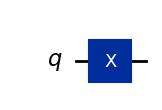

In [7]:
qc_x = QuantumCircuit(1)  # Create circuit object with 1 qubitt
qc_x.x(0)                   # Add X gate to circuit
qc_x.draw("mpl")

We need the `Operator` class in `quantum_info` to extract matrices.

In [8]:
from qiskit.quantum_info import Operator

X = Operator(qc_x) # extract the unitary matrix that represents the quantum circuit qc storing
X.draw('latex', prefix='X =')

<IPython.core.display.Latex object>

 The `.evolve()` method performs explicit matrix-vector or matrix-matrix multiplication to calculate how a quantum state changes when passed through an operator, gate, or circuit.

 We now apply the matrix `X` to the states $\ket{0}$ and $\ket{1}$ as follows:

In [9]:
print('Evolution of state |0⟩ over an X gate results in:')
display(zero.evolve(qc_x).draw('latex'))  # Evolving state |0⟩ over X should result in State |1⟩

print('Evolution of state |1⟩ over an X gate results in:')
display(one.evolve(qc_x).draw('latex'))  # Evolving state |1⟩ over X should result in State |0⟩

Evolution of state |0⟩ over an X gate results in:


<IPython.core.display.Latex object>

Evolution of state |1⟩ over an X gate results in:


<IPython.core.display.Latex object>

Now let's create a complete circuit using the X gate, applying it to $\ket{0}$.

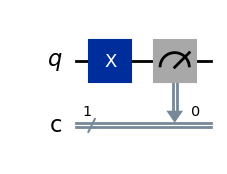

In [10]:
qc_xm = QuantumCircuit(1,1)  # Create circuit object with 1 qubit and 1 classical bit
qc_xm.x(0)                   # Add X gate to circuit to qubit 0
qc_xm.measure(0,0)           # Add measurement gate between qubit 0 and bit 0
qc_xm.draw("mpl")

The `Basicsimulator` allows us to simulate the execution of quantum circuits locally on a classical computer using a pure Python implementation.

In [11]:
from qiskit.providers.basic_provider import BasicSimulator

simulator = BasicSimulator()           # define simulator object
job = simulator.run(qc_xm, shots=1000)  # use run method to execute our circuit some number of shots
result = job.result()                  # extract our results
counts = result.get_counts()           # get the counts from the experiment

print(counts)

{'1': 1000}


We can visualize this using a histogram. For this we need the `plot_histogram` function in Qiskit.

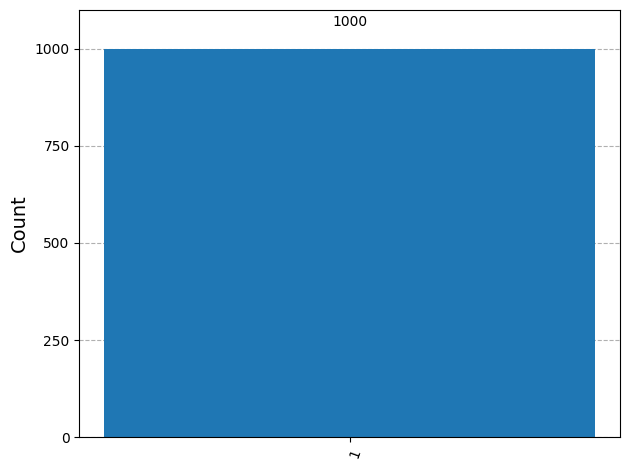

In [12]:
from qiskit.visualization import plot_histogram

plot_histogram(counts)

# Task 2
1. Create a quantum circuit named `qc_xh` with one qubit.
2. Apply the Pauli-X gate
3. Apply the Hadamard gate 
4. Draw the cirucuit
5. Produce the matrix HX that represents the cirucit
6. Display the final state of the circuit



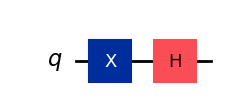

In [13]:
qc_xh = QuantumCircuit(1)  # Create circuit object with 1 qubit and 1 classical bit (step 1 is done for you!)

qc_xh.x(0) #Add X gate to circuit (step 2)
qc_xh.h(0) #Add H gate to circuit (step 3)
 
qc_xh.draw("mpl")           #(setp 4)

In [14]:
HX = Operator(qc_xh)             #(step 5)
HX.draw('latex', prefix='H \\cdot X =') 

<IPython.core.display.Latex object>

In [15]:
print('Result of applying X gate followed by an H gate to state |0⟩:')
display(Statevector(qc_xh).draw('latex'))  # Passing a circuit to the Statevector class, always evolves state |0⟩ (step 6)

Result of applying X gate followed by an H gate to state |0⟩:


<IPython.core.display.Latex object>

## Task 3
1. Create a quantum circuit named `qc_h` with one qubit.
2. Apply the Hadamard gate
4. Measure the final state between qubit 0 and bit 0 
4. Draw the cirucuit
5. Disply the measurement statistics on a Bar chart for 10000 shots


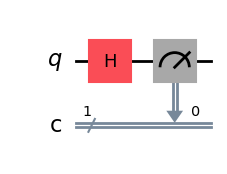

In [16]:
qc_h = QuantumCircuit(1,1)  # Create circuit object with 1 qubitt
qc_h.h(0)                   # Add H gate to circuit
qc_h.measure(0,0)           # Add measurement gate between qubit 0 and bit 0
qc_h.draw("mpl")

In [17]:
simulator = BasicSimulator()           # define simulator object
job = simulator.run(qc_h, shots=1000)  # use run method to execute our circuit some number of shots
result = job.result()                  # extract our results
counts = result.get_counts()           # get the counts from the experiment

print(counts)

{'1': 527, '0': 473}


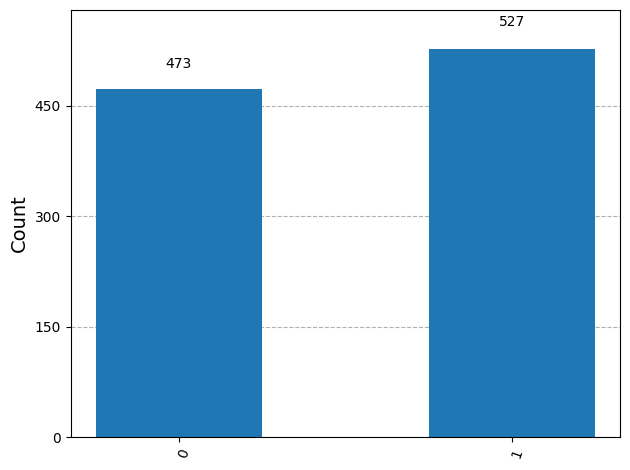

In [18]:
plot_histogram(counts)

## The Bloch Sphere

The Bloch sphere is a three-dimensional figure used to represent all possible states of a quantum system. The axes are: $x$, $y$, and $z$.

Recall, the Pauli gates: X, Y and Z, given by

$ X =\begin {bmatrix} 
0 & 1\\
1 & 0\\
\end{bmatrix}$

$ Y =\begin {bmatrix} 
0 & -i\\
i & 0\\
\end{bmatrix}$

$ Z =\begin {bmatrix} 
1 & 0\\
0 & -1\\
\end{bmatrix}$

We have $X \ket{0} = \ket{1}, X\ket{1} = \ket{0}$, and $Z\ket{0} = \ket{0}, Z \ket{1} = -\ket{1}$

### Task 4: Compute
1. $Y \ket{0}$
2. $Y \ket{1}$

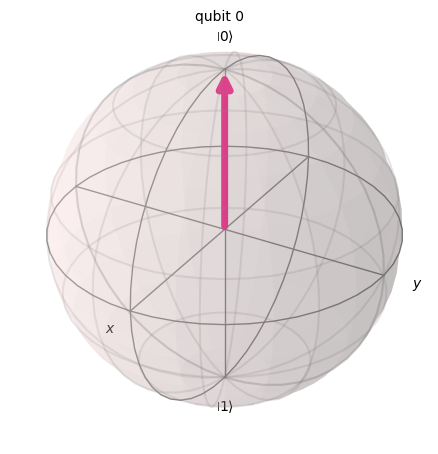

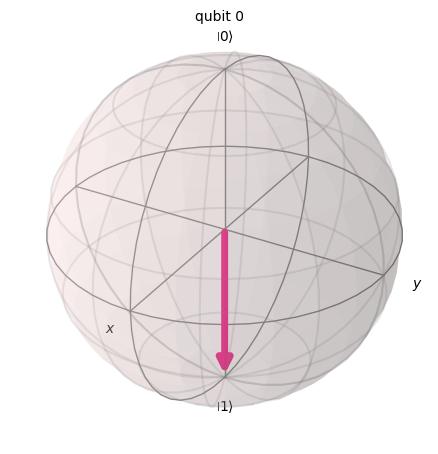

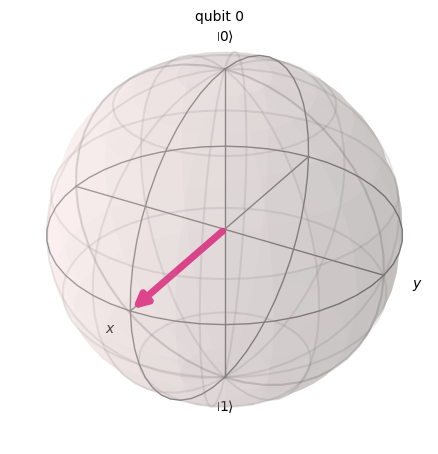

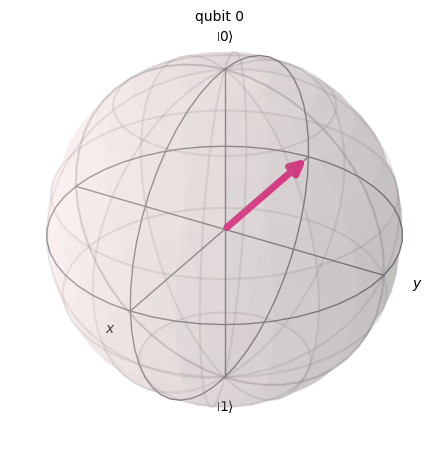

In [19]:
# Display the zero state on a Bloch sphere
display(zero.draw('bloch'))
display(one.draw('bloch'))
display(plus.draw('bloch'))
display(minus.draw('bloch'))




State after X gate:


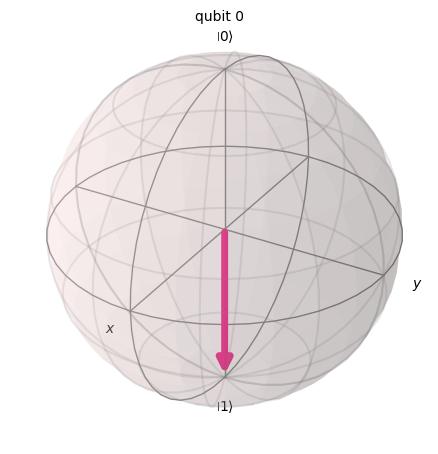

In [20]:
# Apply X gate to |0⟩ and display in Bloch sphere
ket_out = zero.evolve(qc_x)

print('State after X gate:')
display(ket_out.draw('bloch'))

State after X gate:


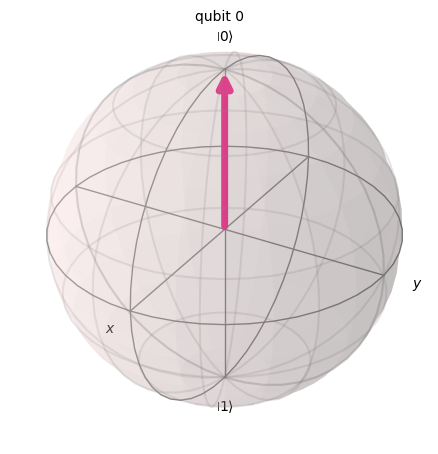

In [21]:
# Apply X gate to |1⟩ and display in Bloch sphere
ket_out = one.evolve(qc_x)

print('State after X gate:')
display(ket_out.draw('bloch'))

Let's repeat this exercise using gate $Z$. First, we create a quantum circuit for the Z gate

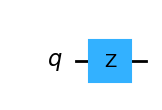

In [22]:
qc_z = QuantumCircuit(1)

qc_z.z(0)

qc_z.draw("mpl")

State after Z gate:


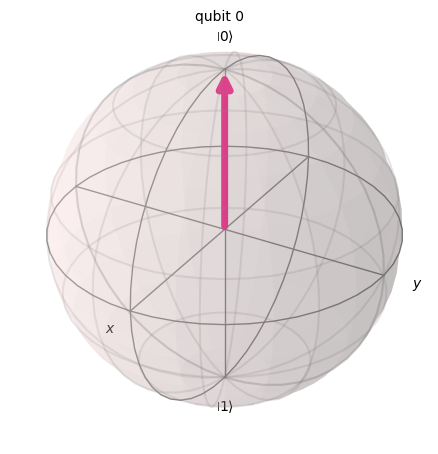

In [23]:
ket_out = zero.evolve(qc_z)
print('State after Z gate:')
display(ket_out.draw('bloch'))

State after Z gate:


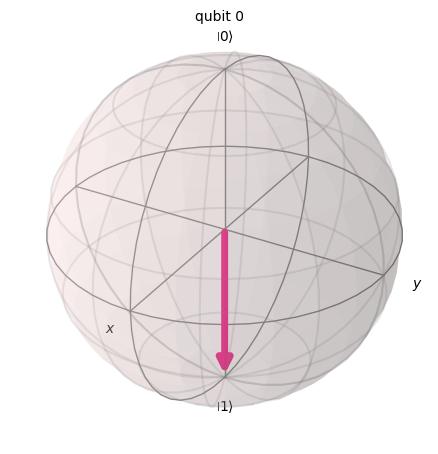

In [24]:
ket_out = one.evolve(qc_z)
print('State after Z gate:')
display(ket_out.draw('bloch'))

State after Z gate:


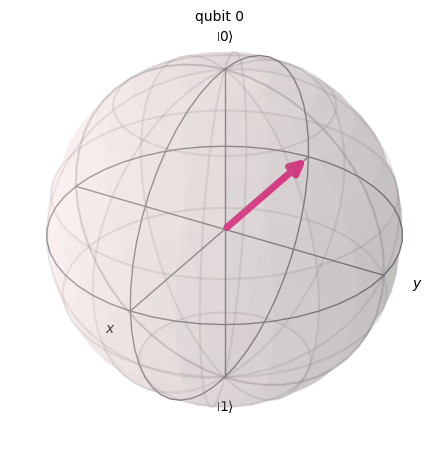

In [25]:
ket_out = plus.evolve(qc_z)
print('State after Z gate:')
display(ket_out.draw('bloch'))

## Task 5
Apply the $Y$ gate to the $\ket{0}$ state and display it on a bloch sphere. Remember, you have to create a quantum circuit for $Y$. What do you notice?

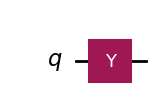

In [26]:
qc_y = QuantumCircuit(1)

qc_y.y(0)

qc_y.draw('mpl')


State after Z gate:


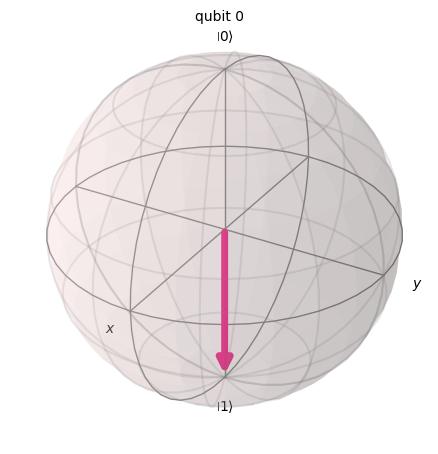

In [27]:
ket_out = zero.evolve(qc_y)
print('State after Z gate:')
display(ket_out.draw('bloch'))

## Task 6
Recall the operator HX in `Task 2`. 
1. Apply it to the $\ket{0}$ state and display on the bloch sphere. You don't have to create another quantum circuit of $HX$, you already have it from `Task 2`. 
2. Use a mathematical calculation to verify you are correct.

State after Z gate:


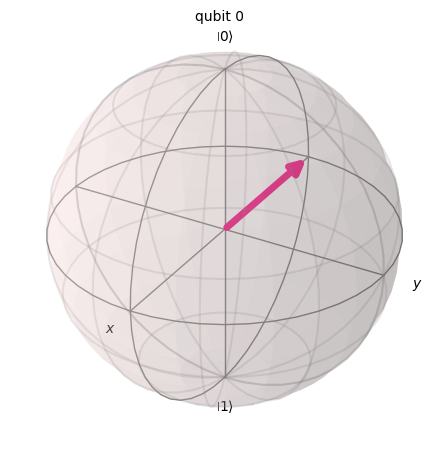

In [28]:
ket_out = zero.evolve(qc_xh)
print('State after Z gate:')
display(ket_out.draw('bloch'))

# MULTI-QUBIT SYSTEMS

These are quantum systems that consist of more than one qubit. Last time we considered this subject, but at a very peripheral level. We restrict just to 2-qubit systems. Now we introduce two key notions:
1. Separable states
2. Entangled states

## Separable States
Consider the qubits $\ket{0}$ and $\ket{1}$. We can combined these using a tensor product to form a new qubit in a larger quantum system




In [29]:

# Define states |0⟩ and |1⟩
state_00 = zero.tensor(zero)    # compose state |0⟩⊗|0⟩
state_01 = zero.tensor(one)    # compose state |0⟩⊗|1⟩
state_10 = one.tensor(zero)    # compose state |1⟩⊗|0⟩
state_11 = one.tensor(one)    # compose state |1⟩⊗|1⟩

# display states in column-vector notation
display(state_00.draw('latex', convention='vector', prefix=r'|0\rangle \otimes |0\rangle = '))
display(state_01.draw('latex', convention='vector', prefix=r'|0\rangle \otimes |1\rangle = '))
display(state_10.draw('latex', convention='vector', prefix=r'|1\rangle \otimes |0\rangle = '))
display(state_11.draw('latex', convention='vector', prefix=r'|1\rangle \otimes |1\rangle = '))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Similarly, for qubits $\ket{+}$ and $\ket{-}$ we have

In [30]:
# Define states |0⟩ and |1⟩
state_plus_plus = plus.tensor(plus)    # compose state |0⟩⊗|0⟩
state_plus_min = plus.tensor(minus)    # compose state |0⟩⊗|1⟩
state_min_plus = minus.tensor(plus)    # compose state |1⟩⊗|0⟩
state_min_min= minus.tensor(minus)    # compose state |1⟩⊗|1⟩

# display states in column-vector notation
display(state_plus_plus.draw('latex', convention='vector', prefix=r'|+\rangle \otimes |+\rangle = '))
display(state_plus_min.draw('latex', convention='vector', prefix=r'|+\rangle \otimes |-\rangle = '))
display(state_min_plus.draw('latex', convention='vector', prefix=r'|-\rangle \otimes |+\rangle = '))
display(state_min_min.draw('latex', convention='vector', prefix=r'|-\rangle \otimes |-\rangle = '))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

Instead of writing $\ket{a} \otimes \ket{b}$, we may just write $\ket{a} \ket{b}$ or $\ket{ab}$.

DEFINITION: A quantum state $\ket{x}$ in a multiqubit system is called `separable` if we can find states $\ket{a}$ and $\ket{b}$ in the subsystems such that $\ket{x} = \ket{a} \otimes \ket{b}$.

Consider the state: $$\ket{x} = \frac{1}{2} \ket{00} - \frac{1}{2} \ket{01} + \frac{1}{2} \ket{10} - \frac{1}{2} \ket{11}$$

Observe that we can rewrite:
\begin{align*}&\frac{1}{2} \ket{00} - \frac{1}{2} \ket{01} + \frac{1}{2} \ket{10} - \frac{1}{2} \ket{11} = \\ 
& \frac{1}{2}\ket{0}\Big(\ket{0}-\ket{1}\Big) + \frac{1}{2} \ket{1} \Big(\ket{0}-\ket{1}\Big) =\\
& \frac{1}{\sqrt{2}}\ket{0}\Big(\frac{\ket{0}-\ket{1}}{\sqrt{2}}\Big) + \frac{1}{\sqrt{2}} \ket{1} \Big(\frac{\ket{0}-\ket{1}}{\sqrt{2}}\Big) =\\
& \frac{1}{\sqrt{2}}\Big( \ket{0} + \ket{1} \Big) \Big( \frac{1}{\sqrt{2}}\Big( \ket{0} - \ket{1} \Big) \Big) = \\
& \ket{+} \ket{-} \end{align*}

We see that $\ket{x} = \ket{+} \otimes \ket{-}$, hence, separable.


The quantum circuit below produces the separable state $\ket{x}$ above.

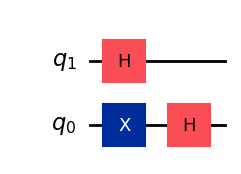

<IPython.core.display.Latex object>

In [31]:
qc_sep = QuantumCircuit(2)    # define quantum circuit
qc_sep.h(1)                   # apply H gate to qubit 1
qc_sep.x(0)                   # apply X gate to qubit 0
qc_sep.h(0)                   # apply H gate to qubit 0

display(qc_sep.draw("mpl", reverse_bits=True))       # draw circuit
display(Statevector(qc_sep).draw("latex"))  # display statevector

We can verify this mathematically in two difference ways:
1. Finding the matrix of the system
2. Using the property of tensor products to keep track of how the system evolves.

In [32]:
Operator(qc_sep).draw("latex")

<IPython.core.display.Latex object>

A quantum state that is NOT separable is called `ENTANGLED`. For example the quantum state $\ket{y} = \frac{1}{\sqrt{2}} \ket{00} + \frac{1}{\sqrt{2}} \ket{11}$ is an entangled state.

Entanglement is the key differentiating factor between classical and quantum systems. To create an entanglement, we use the `CNOT` gate.

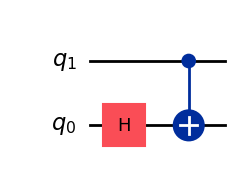

In [33]:
qc_ent = QuantumCircuit(2)

qc_ent.h(0)                   # apply H gate to qubit 1
qc_ent.cx(1,0)                # apply CX with control on q1 and target on q0

display(qc_ent.draw("mpl", reverse_bits=True)) 

In [34]:
Operator(qc_ent).draw('latex')

<IPython.core.display.Latex object>

# ```Summary```
The state of a qubit is transformed by application of a quantum gate (that is, a unitary operator). In particular,
1. the Hadamard gate (H) creates a superposition
2. the Pauli-X gate flips a qubit
3. the CNOT gate creates an entanglement

# ```Further Reading```

The following resources will be helful:
1. [`Learn Quantum Computing using Python` by Diego Emilio Serrano](https://learnquantum.io/#)  
2. [`Understanding Quantum Information and Computation` by John Watrous](https://arxiv.org/abs/2507.11536) 

These resources provide an excellent foundation for exploring quantum computing and offer valuable insights into more advanced topics in quantum information and computation. Readers are encouraged to consult them for a deeper understanding of the concepts presented in this notebook.

# ```References```
1. Serrano, D. E. Learn Quantum Computing Using Python: Available at https://learnquantum.io/
2. Watrous, J. Understanding Quantum Information and Computation. arXiv preprint arXiv:2507.11536. Available at : https://arxiv.org/abs/2507.11536